<a href="https://colab.research.google.com/github/lalevel/dotfiles/blob/master/ML101/CodingOurFirstMLModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Coding Our Model

Before we begin, go to Tools > Settings > Editor and check "Show line numbers." It'll help you follow along with the instructions in the lesson.

### Graphing the Data
This takes us right to where we left off. Make sure you remember how everything works.

Text(0, 0.5, 'Smartcase Grade')

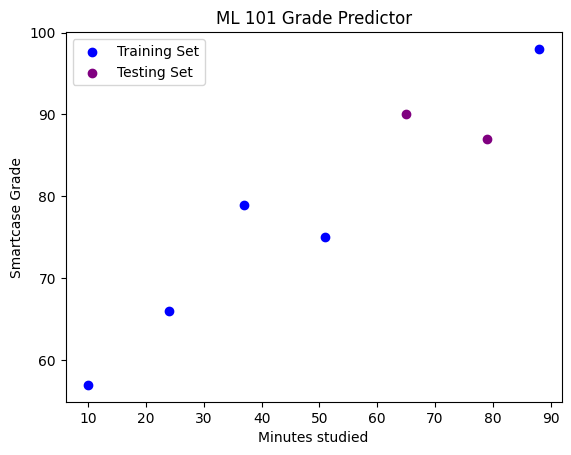

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

X = np.array([10,24,37,51,65,79,88])
y = np.array([57,66,79,75,90,87,98])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)

plt.scatter(X_train, y_train, color="blue", label="Training Set")
plt.scatter(X_test, y_test, color="purple", label="Testing Set")
plt.title("ML 101 Grade Predictor")
plt.legend()
plt.xlabel("Minutes studied")
plt.ylabel("Smartcase Grade")

### Creating the LinearRegression Class

In [11]:
class LinearRegression():

  def __init__(self, learning_rate=0.01, n_iterations=1000):
    # Hyperparameters
    self.learning_rate = learning_rate
    self.n_iterations = n_iterations

    # Parameters (initialized during training once feature count is known)
    self.w = None
    self.b = None

  def predict(self, X):
    # Linear regression formula: y_hat = Xw + b
    y_predicted = np.dot(X, self.w) + self.b
    return y_predicted

  def train(self, X, y):
    # m = number of training examples, n = number of features
    m, n = X.shape

    # Initialize weights to zeros and bias to 0
    self.w = np.zeros(n)
    self.b = 0

    # Gradient descent loop
    for _ in range(self.n_iterations):
      # 1. Get the prediction
      y_predicted = self.predict(X)

      # 2. Compute gradients (derivatives of the MSE cost function)
      dw = (1 / m) * np.dot(X.T, (y_predicted - y))
      db = (1 / m) * np.sum(y_predicted - y)

      # 3. Update parameters
      self.w -= self.learning_rate * dw
      self.b -= self.learning_rate * db

  def mse(self, y_predicted, y):
    # Mean Squared Error formula
    return np.mean((y - y_predicted) ** 2)

### Instantiating the Class

In [12]:
# 0. Reshape to 2D and standardize (use training stats only)
X_train_2d = X_train.reshape(-1, 1)
X_test_2d = X_test.reshape(-1, 1)

mu, sigma = X_train_2d.mean(axis=0), X_train_2d.std(axis=0)
X_train_s = (X_train_2d - mu) / sigma
X_test_s = (X_test_2d - mu) / sigma

# 1. Instantiate (0.1 is fine on standardized features)
grade_predictor = LinearRegression(learning_rate=0.1, n_iterations=1000)
# 2. Train
grade_predictor.train(X_train_s, y_train)
# 3. Predict on unseen test features
smartcase_predictions = grade_predictor.predict(X_test_s)
# 4. Evaluate
mse_value = grade_predictor.mse(smartcase_predictions, y_test)
print("Test MSE:", mse_value)

Test MSE: 26.85267000917997


### Graphing the Model

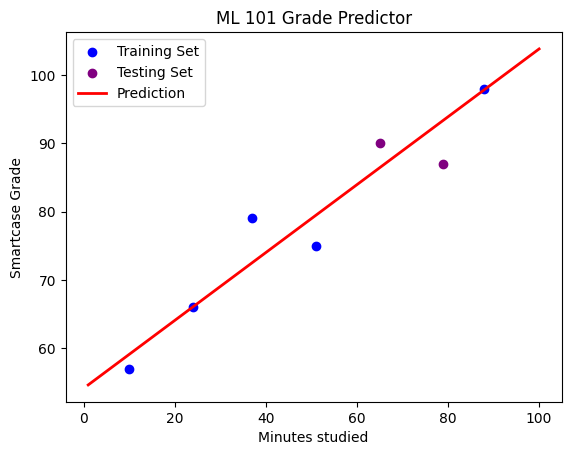

MSE of our test set: 26.85267000917997
Model's parameters are: w: 0.497, b: 54.106


In [14]:
plt.scatter(X_train, y_train, color="blue", label="Training Set")
plt.scatter(X_test, y_test, color="purple", label="Testing Set")

x_data = np.linspace(1, 100, 100)
w_orig = grade_predictor.w[0] / sigma[0]
b_orig = grade_predictor.b - grade_predictor.w[0] * mu[0] / sigma[0]
plt.plot(x_data, w_orig * x_data + b_orig, color="red", linewidth=2, label="Prediction")

plt.title("ML 101 Grade Predictor")
plt.xlabel("Minutes studied")
plt.ylabel("Smartcase Grade")
plt.legend()   # after plot(), so "Prediction" shows up in the legend
plt.show()

print(f"MSE of our test set: {mse_value}")
print(f"Model's parameters are: w: {w_orig:.3f}, b: {b_orig:.3f}")

### Deploying the Model

In [15]:
minutes = 60  # put the number of minutes you plan to study here

# Standardize with the training stats, then predict
your_grade = grade_predictor.predict((np.array([[minutes]]) - mu) / sigma)[0]

# Clip to the valid grade range
your_grade = min(max(your_grade, 0), 100)

print(f"Our model predicts you'll earn a {round(your_grade, 1)}% on the upcoming Quantic Smartcase.")
print(f"Formula used to make this prediction: y = {round(w_orig, 3)}x + {round(b_orig, 3)}")

Our model predicts you'll earn a 84.0% on the upcoming Quantic Smartcase.
Formula used to make this prediction: y = 0.497x + 54.106
